# Feature Scaling and Encodings


Feature preparation changes columns into forms that a model can use. This notebook follows the notes from feature engineering to scaling, then encoding categorical data.


<!-- Source transcription: transcription/10.1.md -->
## Feature engineering

Feature engineering includes transforming existing columns, constructing new ones, selecting useful inputs, and extracting a smaller representation. The notes also connect missing values, categories, outliers, and scaling to this preparation stage.


Missing values may be filled or rows/columns removed; the choice depends on how much is missing and what the column means. Outliers need inspection before removal. These topics have dedicated later notebooks, so here we focus on scaling and encoding.


A constructed feature combines or changes existing information. In the Titanic example, `SibSp + Parch` can give a simple family-size feature; whether it helps should be checked with a sound evaluation.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

import pandas as pd

titanic_path = Path("init_code/day19-understanding-your-data-descriptive-stats/train.csv")
if not titanic_path.exists():
    titanic_path = Path("../init_code/day19-understanding-your-data-descriptive-stats/train.csv")
titanic = pd.read_csv(titanic_path)
titanic["FamilySize"] = titanic["SibSp"] + titanic["Parch"] + 1
titanic[["SibSp", "Parch", "FamilySize"]].head()


`FamilySize` is a small feature-construction example. The added `1` counts the passenger; domain knowledge should guide the definition, and model validation should decide whether it is useful.


Feature selection keeps a subset of input columns. Feature extraction transforms existing columns into a smaller set of combined features; PCA is one example and is explored later in the course.


<!-- Source transcription: transcription/10.2.md -->
## Feature extraction and PCA

PCA rotates the coordinate axes toward directions with more variance, then can keep only the most useful directions. This can reduce the number of inputs and some noise, but the new features are combinations of the originals and may be harder to interpret.


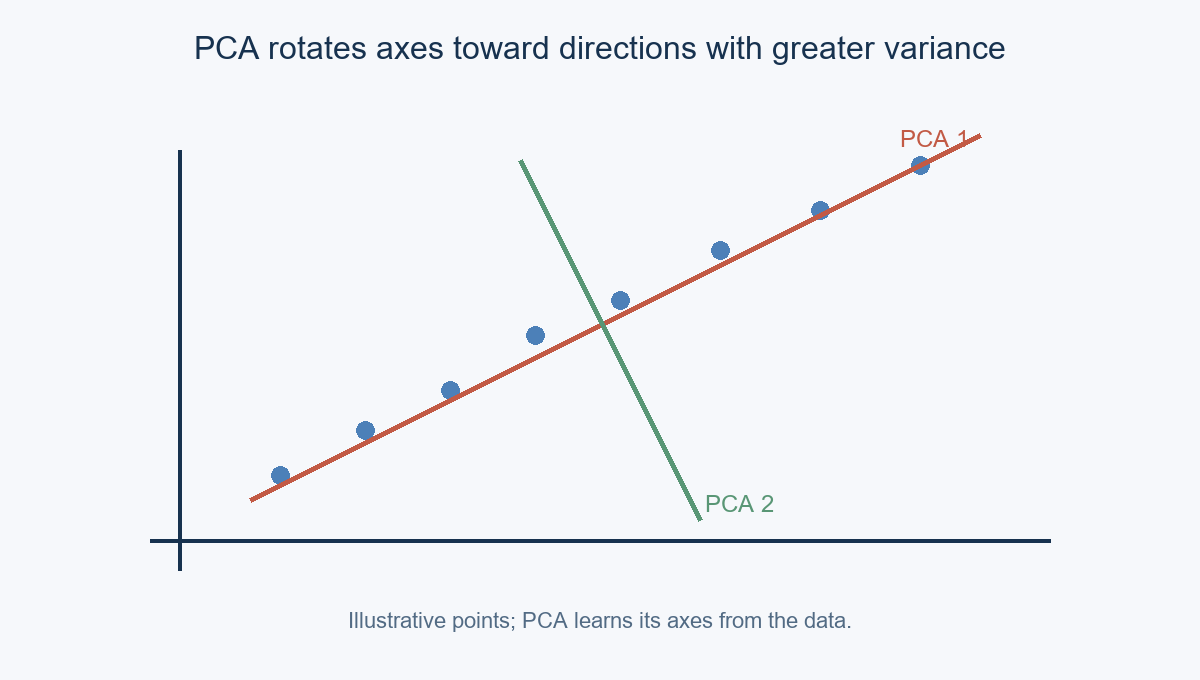

<!-- Source transcription: transcription/10.3.md -->
## Why scale features?

Distance-based methods such as KNN can be dominated by a feature measured in larger units. For two points, Euclidean distance is $d = \sqrt{(x_2-x_1)^2 + (y_2-y_1)^2}$; a large salary difference can outweigh a smaller age difference.


In [ ]:
import numpy as np

# Two passengers: age in years and salary in dollars
p1 = np.array([27, 48_000])
p2 = np.array([50, 83_000])
raw_distance = np.linalg.norm(p2 - p1)
print(f"Raw distance: {raw_distance:,.1f}")
print("Age contribution:", (p2[0] - p1[0]) ** 2)
print("Salary contribution:", (p2[1] - p1[1]) ** 2)


The squared salary difference overwhelms the age term because dollars have a much larger numerical scale. Scaling makes units comparable for distance based methods; it does not make every feature equally useful.


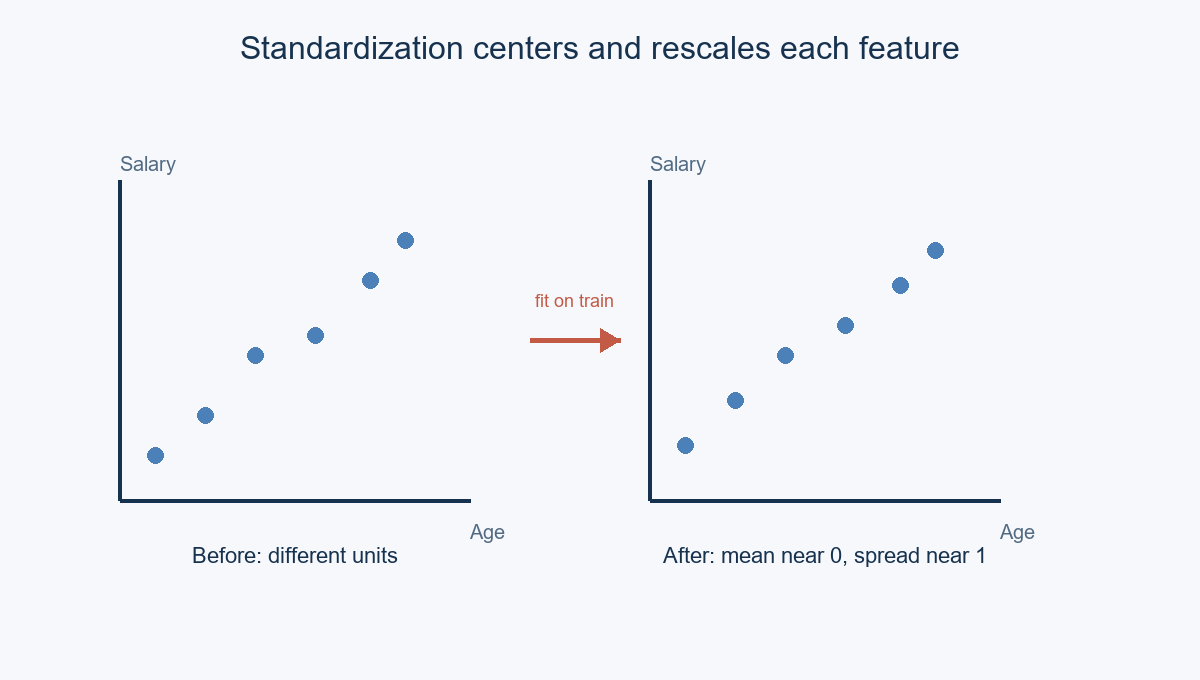

<!-- Source transcription: transcription/10.4.md -->
## Standardization

Standardization subtracts the training mean and divides by the training standard deviation: $z = (x - \mu) / \sigma$. A transformed feature is centered near zero with standard deviation near one; the distribution shape and outlier status remain.


Split first, fit the scaler on training data, then use that fitted scaler to transform both sets. This keeps information from the test set out of preprocessing.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ads_path = Path("init_code/day24-standardization/Social_Network_Ads.csv")
if not ads_path.exists():
    ads_path = Path("../init_code/day24-standardization/Social_Network_Ads.csv")
ads = pd.read_csv(ads_path)
X = ads[["Age", "EstimatedSalary"]]
y = ads["Purchased"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=0, stratify=y
)
standard_scaler = StandardScaler()
X_train_std = standard_scaler.fit_transform(X_train)
X_test_std = standard_scaler.transform(X_test)
print("Train means:", X_train_std.mean(axis=0).round(2))
print("Train standard deviations:", X_train_std.std(axis=0).round(2))
print("Shapes:", X_train.shape, X_train_std.shape, X_test_std.shape)


The training means and standard deviations are approximately 0 and 1, and the shape stays the same. The same training-set parameters are applied to test data, even if its transformed averages are not exactly zero.


<!-- Source transcription: transcription/11.1.md -->
## Where scaling helps

Scaling commonly matters for KNN, K-Means, PCA, neural networks, and gradient-based optimization. Tree models split by thresholds, so scaling usually does not change their decisions.


Standardization does not remove outliers. If a feature contains extreme values, inspect them and consider a robust scaler; do not expect scaling alone to fix them.


<!-- Source transcription: transcription/11.2.md -->
## Normalization methods

Min-Max scaling maps values into a chosen interval, commonly $[0, 1]$: $x' = (x - x_{min}) / (x_{max} - x_{min})$. It uses observed minimum and maximum values, so outliers can compress most of the data.


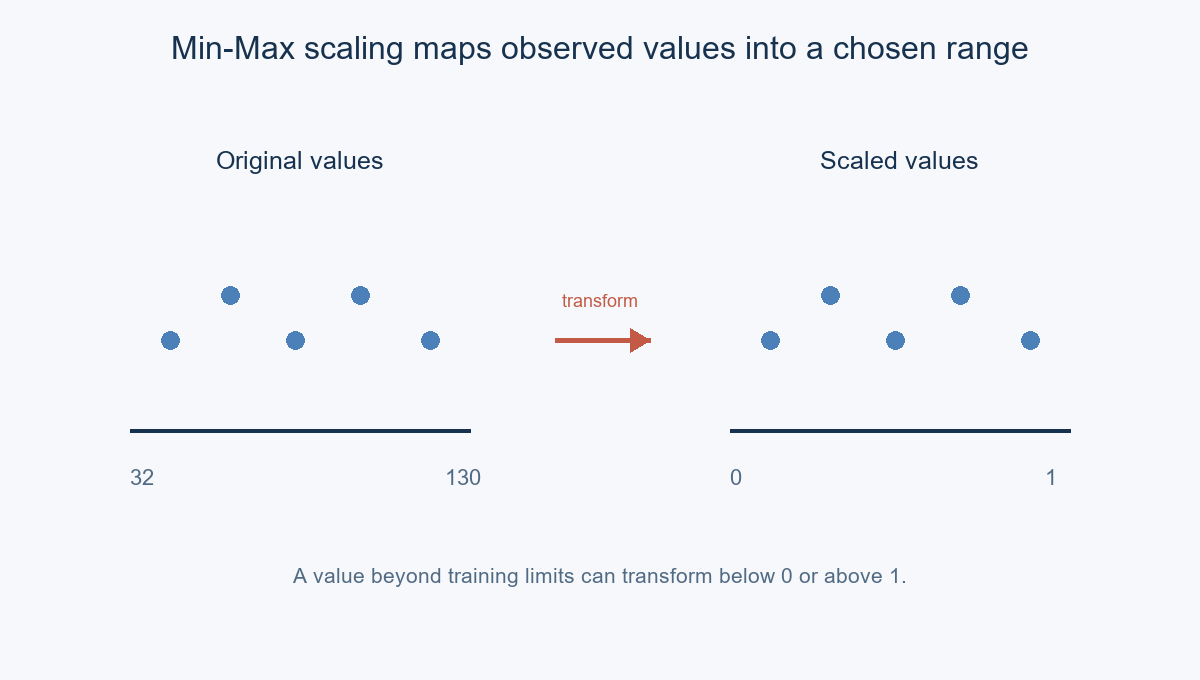

In [ ]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()
X_train_minmax = minmax.fit_transform(X_train)
X_test_minmax = minmax.transform(X_test)
print("Training minima:", X_train_minmax.min(axis=0).round(2))
print("Training maxima:", X_train_minmax.max(axis=0).round(2))
print("Test values can fall outside [0, 1]:",
      ((X_test_minmax < 0) | (X_test_minmax > 1)).any())


The training features map to 0–1. Test values can fall outside that range when they are beyond the training minimum or maximum; the scaler does not clip them by default.


<!-- Source transcription: transcription/11.3.md -->
Mean normalization subtracts the mean and divides by the range. MaxAbsScaler divides by the largest absolute value and keeps zeros at zero, which is useful for sparse data. RobustScaler centers by the median and scales by the interquartile range, so extreme values have less influence.


In [ ]:
from sklearn.preprocessing import MaxAbsScaler, RobustScaler

# Compare the different scaling choices on the same training features
robust = RobustScaler()
max_abs = MaxAbsScaler()
X_train_robust = robust.fit_transform(X_train)
X_train_maxabs = max_abs.fit_transform(X_train)

def mean_normalize(train, other):
    mean = train.mean(axis=0)
    value_range = train.max(axis=0) - train.min(axis=0)
    value_range[value_range == 0] = 1  # avoid division by zero for constant columns
    return (train - mean) / value_range, (other - mean) / value_range

X_train_mean_norm, X_test_mean_norm = mean_normalize(X_train, X_test)
print("Shapes:", X_train_robust.shape, X_train_maxabs.shape, X_train_mean_norm.shape)


Try a scaler that fits the algorithm and data. Standardization is a common starting point; Min-Max fits known bounded ranges, RobustScaler helps when outliers matter, and MaxAbsScaler preserves sparse zeros. Compare them using validation data.


<!-- Source transcription: transcription/11.4.md -->
## Encoding categorical data

Machine learning models need numerical inputs. Nominal categories have no natural order, while ordinal categories do. Choose an encoding that preserves that meaning.


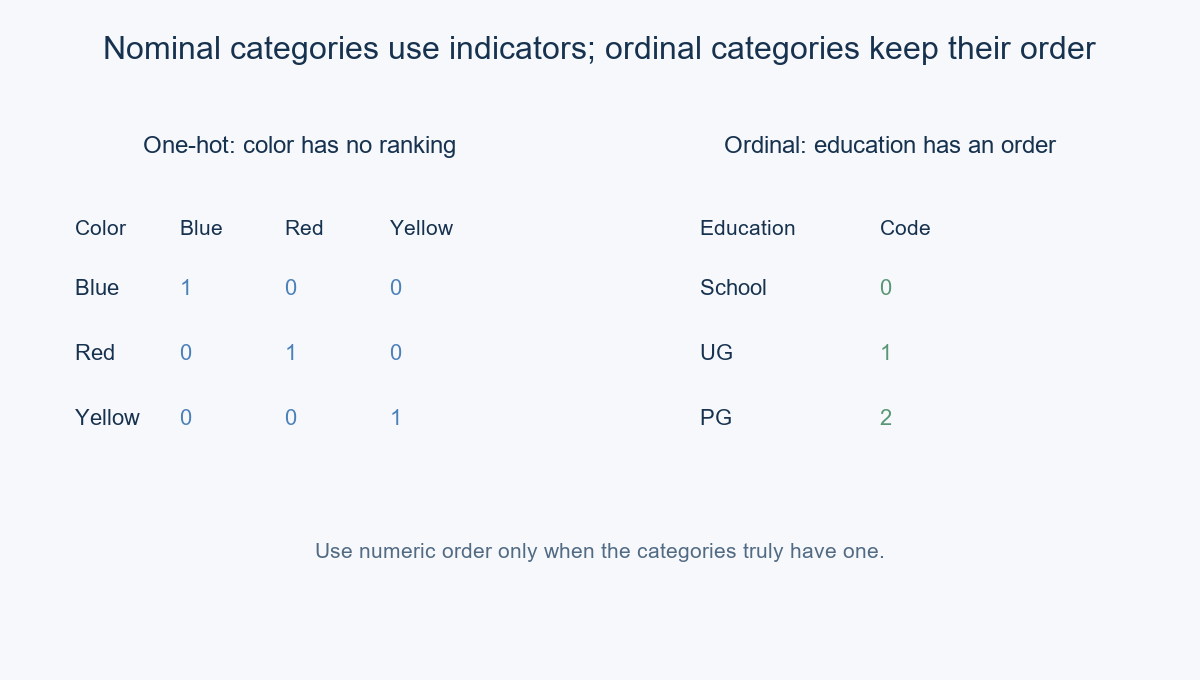

Ordinal encoding assigns numbers in a meaningful order, such as School < UG < PG. One-hot encoding creates a separate indicator column for each nominal category, such as fuel type or color.


In [ ]:
from sklearn.preprocessing import OrdinalEncoder

education_order = [["School", "UG", "PG"]]
ordinal = OrdinalEncoder(categories=education_order)
education = pd.DataFrame({"education": ["UG", "School", "PG", "UG"]})
ordinal.fit_transform(education)


The order is supplied explicitly, so the assigned values carry the intended ranking. Do not use ordinal codes for categories without a real order; the numbers would suggest a comparison that does not exist.


<!-- Source transcription: transcription/12.1.md -->
### Encoding the target

Label encoding is for a classification target (`y`), such as Yes/No. For ordered input columns use OrdinalEncoder; for nominal input columns use OneHotEncoder. Fit encoders on training data and reuse them for test data.


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_train_text = pd.Series(["No", "Yes", "No", "Yes"])
y_test_text = pd.Series(["Yes", "No"])
y_train_encoded = label_encoder.fit_transform(y_train_text)
y_test_encoded = label_encoder.transform(y_test_text)
print("Classes:", label_encoder.classes_)
print("Train:", y_train_encoded, " Test:", y_test_encoded)


LabelEncoder learns the classes from the training target, then maps the test labels with the same mapping. Avoid applying it to nominal input columns, where the resulting numeric order would be misleading.


<!-- Source transcription: transcription/12.1.md -->
## One-hot encoding

One-hot encoding turns each category into a 0/1 indicator. With $k$ categories it can create $k$ columns; dropping one column can avoid perfect linear dependence in some linear models.


The notes call the redundant-column issue the dummy-variable trap: with an intercept, all $k$ indicators sum to one, so one column is determined by the others. Dropping one category removes that exact dependence, though regularized linear models can also handle collinearity.


<!-- Source transcription: transcription/12.2.md -->
### Many categories

When a column has many rare categories, grouping infrequent values under `uncommon` can reduce the number of one-hot columns. Choose the cutoff from the training data and apply the learned grouping to validation and test data.


In [ ]:
cars_path = Path("init_code/day27-one-hot-encoding/cars.csv")
if not cars_path.exists():
    cars_path = Path("../init_code/day27-one-hot-encoding/cars.csv")
cars = pd.read_csv(cars_path)
counts = cars["brand"].value_counts()
rare_brands = counts[counts <= 100].index
cars["brand_grouped"] = cars["brand"].where(~cars["brand"].isin(rare_brands), "uncommon")
print("Original brands:", cars["brand"].nunique())
print("Grouped categories:", cars["brand_grouped"].nunique())
cars["brand_grouped"].value_counts().head()


In [ ]:
car_dummies = pd.get_dummies(cars[["fuel", "owner"]], drop_first=True, dtype=int)
car_dummies.head()


`drop_first=True` removes one indicator per column, which can help avoid perfect collinearity in some linear models. `get_dummies()` is convenient for exploration; a fitted encoder is safer when the same columns must be produced for new data.


Grouping rare brands shrinks the category list. In a real train/test workflow, learn the rare-brand list from training rows only so test data does not influence preprocessing.


Pandas `get_dummies()` is quick for exploration. For repeatable model workflows, an encoder object keeps track of fitted categories; `ColumnTransformer` can combine encoders and numeric transformations in one step, which is covered in the next notebook.


<!-- Source transcription: transcription/12.3.md -->
## Keep the encoded data together

After encoding selected columns, combine them with the numerical columns that were not encoded. The original notes use horizontal stacking (`hstack`) for this step; the next notebook shows how a column transformer can do the work together while preserving a consistent train/test transformation.


In [ ]:
from sklearn.preprocessing import OneHotEncoder

colors = pd.DataFrame({"color": ["Yellow", "Blue", "Red", "Yellow", "Red"]})
# Fit on training rows only; ignore a category not seen during fitting.
color_train = colors.iloc[:4]
color_test = colors.iloc[4:]
one_hot = OneHotEncoder(handle_unknown="ignore", drop="first")
color_train_encoded = one_hot.fit_transform(color_train[["color"]])
color_test_encoded = one_hot.transform(color_test[["color"]])
print("Categories:", one_hot.categories_)
print("Training matrix:\n", color_train_encoded.toarray())
print("Test shape:", color_test_encoded.shape)


The encoder keeps the category mapping learned from training data and applies it to later rows. Dropping one category is useful for some linear models; it is not required for every algorithm.


In [ ]:
import numpy as np

# Small example of joining untouched numeric columns with encoded categories
other_features = np.array([[12000], [18000], [9000], [15000]])
joined = np.hstack([other_features, color_train_encoded.toarray()])
print("Combined shape:", joined.shape)
joined


The output columns contain the untouched numeric feature followed by the encoded indicators. For production workflows, use a fitted transformer so column order and categories stay consistent.
